In [ ]:
!pip install -q tensorflow-datasets seaborn scikit-learn

In [ ]:
!pip install -U importlib_resources tensorflow-datasets

## 1. Descripción del dataset

Para este proyecto se utiliza **TF Flowers**, un conjunto de datos de imágenes de flores disponible mediante TensorFlow Datasets.

El dataset contiene 3.670 imágenes distribuidas en cinco clases: margaritas (*daisy*), dientes de león (*dandelion*), rosas (*roses*), girasoles (*sunflowers*) y tulipanes (*tulips*).

El objetivo es entrenar un modelo de Deep Learning capaz de clasificar una imagen dentro de una de estas cinco categorías.

## 2. Preparación de los datos

Las imágenes se redimensionan a 128 × 128 píxeles y sus valores se normalizan al intervalo [0, 1]. Los datos se dividen en entrenamiento (70 %), validación (15 %) y prueba (15 %).

Se aplica aumento de datos mediante volteo horizontal, rotación y zoom para mejorar la capacidad de generalización del modelo.

In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 15

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [ ]:
(train_raw, val_raw, test_raw), info = tfds.load(
    "tf_flowers",
    split=[
        "train[:70%]",
        "train[70%:85%]",
        "train[85%:]"
    ],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names

print("Clases:", class_names)
print("Entrenamiento:", tf.data.experimental.cardinality(train_raw).numpy())
print("Validación:", tf.data.experimental.cardinality(val_raw).numpy())
print("Prueba:", tf.data.experimental.cardinality(test_raw).numpy())

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Clases: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Entrenamiento: 2569
Validación: 551
Prueba: 550


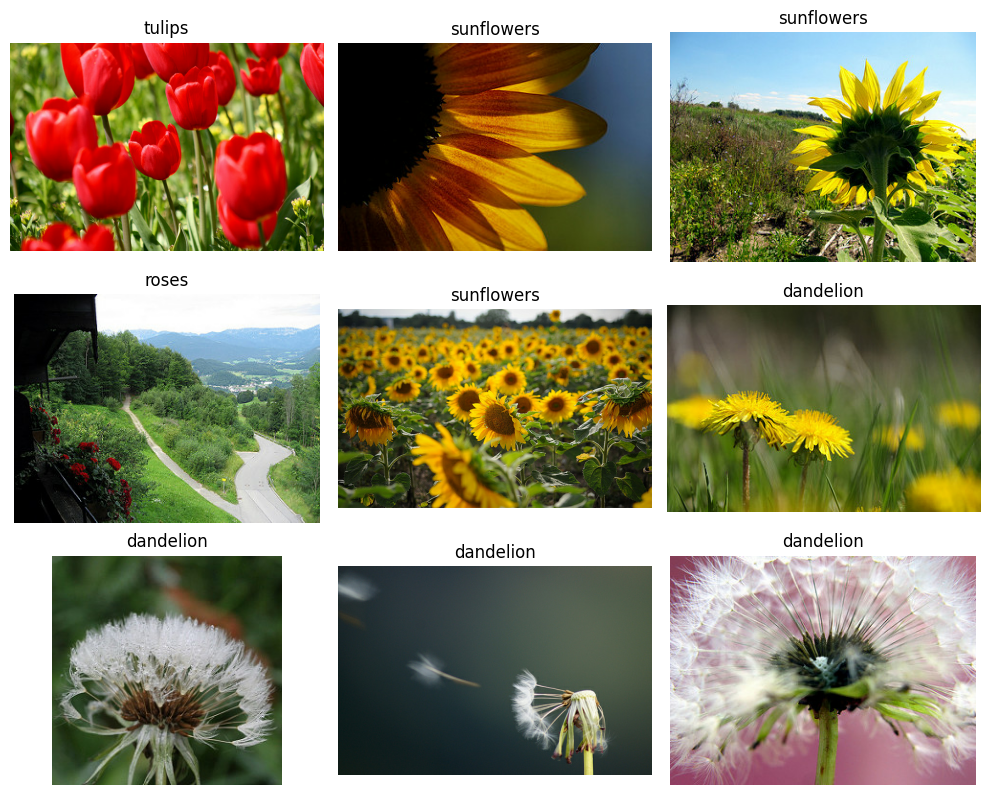

In [ ]:
plt.figure(figsize=(10, 8))

for i, (imagen, etiqueta) in enumerate(train_raw.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(imagen)
    plt.title(class_names[int(etiqueta)])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def preparar_imagen(imagen, etiqueta):
    imagen = tf.image.resize(imagen, IMG_SIZE)
    imagen = tf.cast(imagen, tf.float32) / 255.0
    return imagen, etiqueta

train_ds = (
    train_raw
    .map(preparar_imagen, num_parallel_calls=AUTOTUNE)
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_raw
    .map(preparar_imagen, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_raw
    .map(preparar_imagen, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
])

model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.35),

    layers.Dense(64, activation="relu"),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,829 (397.77 KB)

 Trainable params: 101,829 (397.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "models/mejor_modelo.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.3534 - loss: 1.4454 - val_accuracy: 0.3848 - val_loss: 1.3223
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.4476 - loss: 1.2567 - val_accuracy: 0.5027 - val_loss: 1.1854
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.4955 - loss: 1.1841 - val_accuracy: 0.4791 - val_loss: 1.2930
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.5076 - loss: 1.1533 - val_accuracy: 0.5009 - val_loss: 1.2058
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - accuracy: 0.5598 - loss: 1.0998 - val_accuracy: 0.5064 - val_loss: 1.2060
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 113s 1s/step - accuracy: 0.5524 - loss: 1.0714 - val_accuracy: 0.5354 - val_loss: 1.1607
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.5800 - loss: 1.0347 - val_accuracy: 0.5426 - val_loss: 1.1481
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.5784 - loss: 1.0294 - val_accuracy: 0.4973 - v

In [ ]:
## MEJORAR EL MODELO

import os
import tensorflow as tf
from tensorflow.keras import layers, Model

# Configuración
IMG_SIZE = 128
NUM_CLASSES = len(class_names)

os.makedirs("models", exist_ok=True)

# Base preentrenada: no entrenamos sus millones de parámetros inicialmente
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

# Nueva arquitectura
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Aumentación solo durante el entrenamiento
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomZoom(0.10)(x)

# Tus imágenes ya están normalizadas entre 0 y 1.
# MobileNetV2 espera valores entre -1 y 1.
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "models/mejor_modelo.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

# Guardar los pesos del mejor modelo y la arquitectura
model.save("models/modelo_flores.keras")

print("Mejor accuracy de validación:",
      f"{max(history.history['val_accuracy']):.2%}")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.4693 - loss: 1.4005
Epoch 1: val_accuracy improved from None to 0.76225, saving model to models/mejor_modelo.keras

Epoch 1: finished saving model to models/mejor_modelo.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 59s 648ms/step - accuracy: 0.6166 - loss: 1.0194 - val_accuracy: 0.7623 - val_loss: 0.6076 - learning_rate: 0.0010
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 512ms/step - accuracy: 0.7951 - loss: 0.5722
Epoch 2: val_accuracy improved from 0.76225 to 0.83848, saving model to models/mejor_modelo.keras

Epoch 2: finished saving model to models/mejor_modelo.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 53s 649ms/step - accuracy: 0.8003 - loss: 0.5586 - val_accuracy: 0.8385 - val_loss: 0.5107 - learning_rate: 0.0010
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 520ms/step - accuracy: 0.8383 - loss: 0.4740
Epoch 3: val_accuracy improved from 0.83848 to 0.84755, saving model to models/mejor_modelo.ke

In [ ]:
import tensorflow as tf

# Cargar el mejor modelo de MobileNetV2
model = tf.keras.models.load_model(
    "models/mejor_modelo.keras"
)

# Evaluar con el conjunto de prueba
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Loss de prueba: {test_loss:.4f}")
print(f"Precisión de prueba: {test_accuracy:.2%}")

18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 474ms/step - accuracy: 0.8764 - loss: 0.3479
Loss de prueba: 0.3479
Precisión de prueba: 87.64%


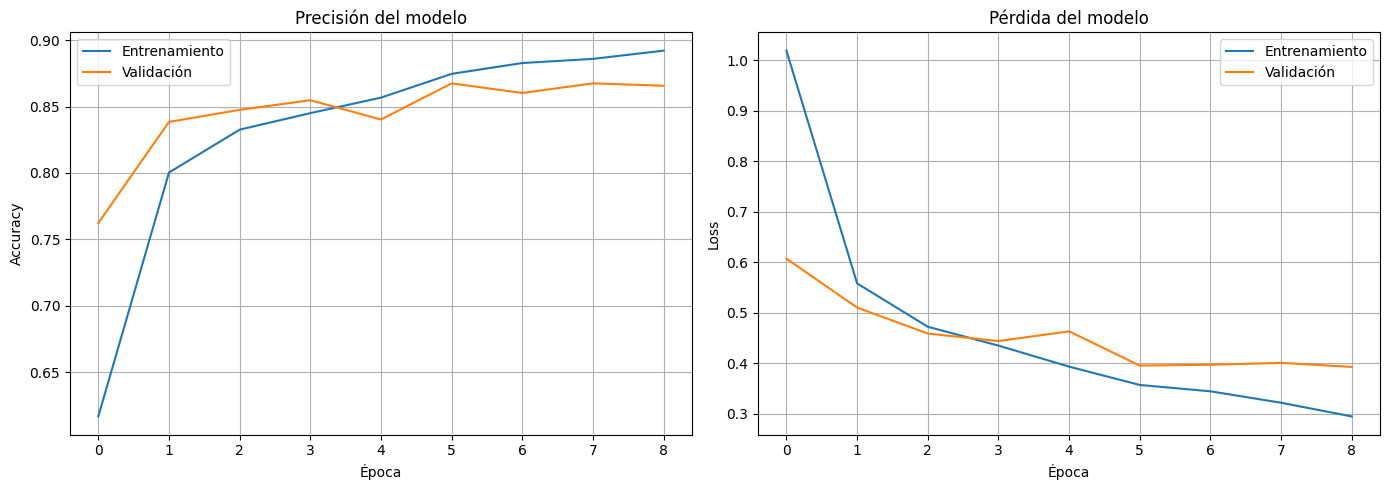

In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precisión
axes[0].plot(history.history["accuracy"], label="Entrenamiento")
axes[0].plot(history.history["val_accuracy"], label="Validación")
axes[0].set_title("Precisión del modelo")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Pérdida
axes[1].plot(history.history["loss"], label="Entrenamiento")
axes[1].plot(history.history["val_loss"], label="Validación")
axes[1].set_title("Pérdida del modelo")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("results/graficas_entrenamiento.png", dpi=150)
plt.show()


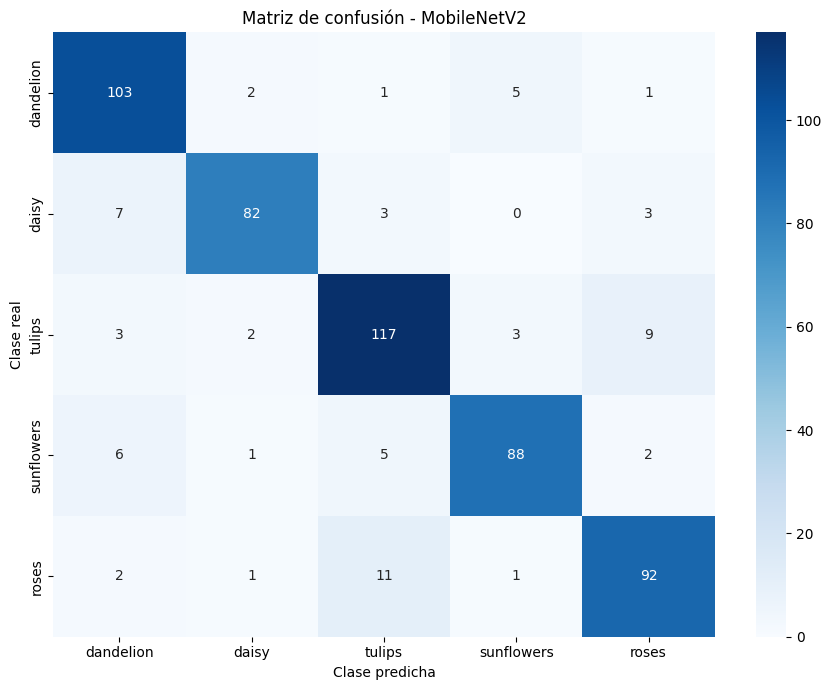

              precision    recall  f1-score   support

   dandelion       0.85      0.92      0.88       112
       daisy       0.93      0.86      0.90        95
      tulips       0.85      0.87      0.86       134
  sunflowers       0.91      0.86      0.88       102
       roses       0.86      0.86      0.86       107

    accuracy                           0.88       550
   macro avg       0.88      0.88      0.88       550
weighted avg       0.88      0.88      0.88       550



In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().astype(int))
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Matriz de confusión - MobileNetV2")
plt.tight_layout()
plt.savefig("results/matriz_confusion.png", dpi=150)
plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

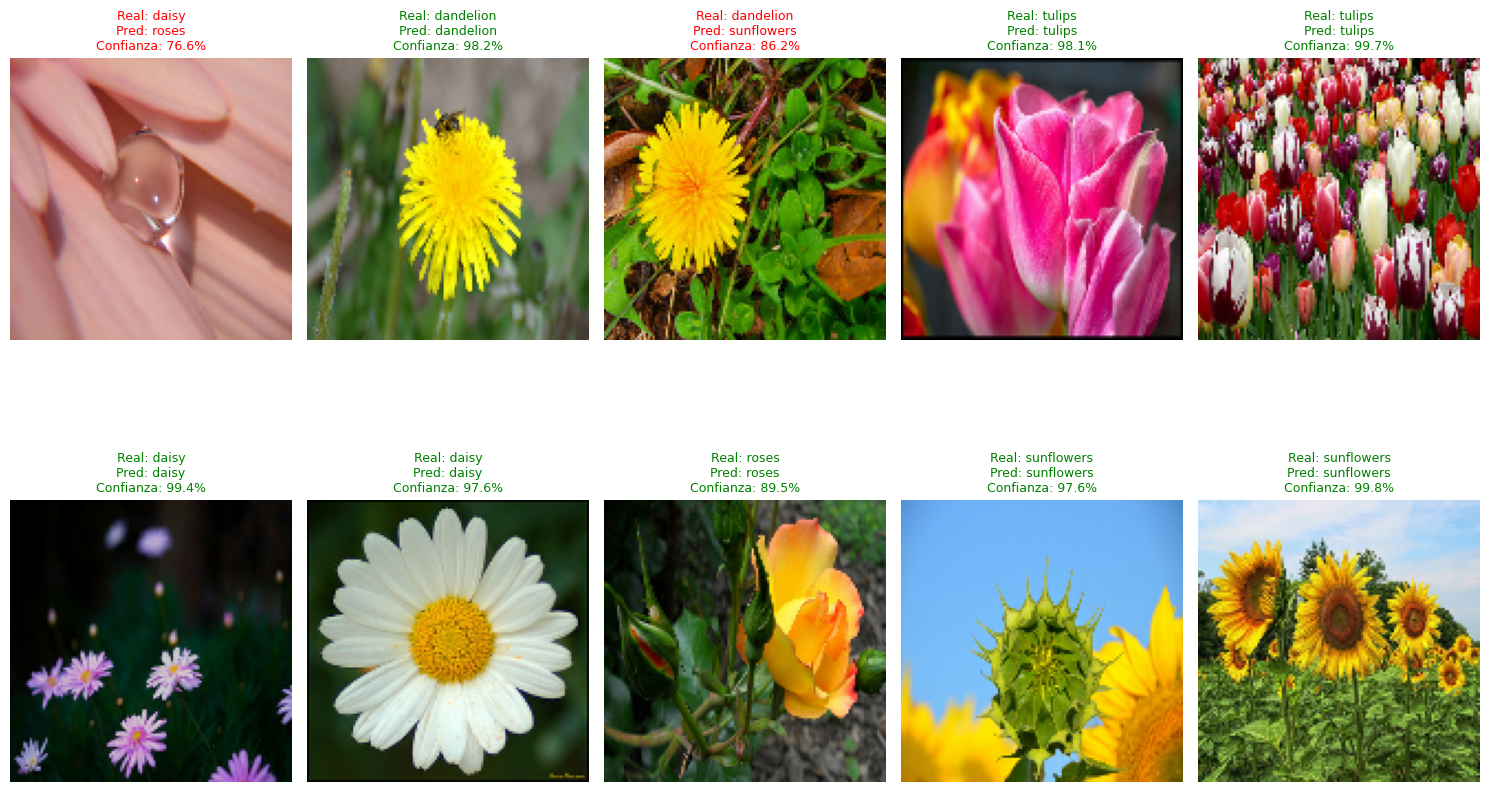

In [ ]:

plt.figure(figsize=(15, 10))

images, labels = next(iter(test_ds))
predictions = model.predict(images[:10], verbose=0)

for i in range(10):
    real_label = int(labels[i].numpy())
    pred_label = int(np.argmax(predictions[i]))
    confidence = float(np.max(predictions[i]))

    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy())

    color = "green" if real_label == pred_label else "red"

    plt.title(
        f"Real: {class_names[real_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Confianza: {confidence:.1%}",
        color=color,
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig("results/predicciones_10.png", dpi=150)
plt.show()

In [ ]:
import tensorflow as tf

# Cargar el modelo con la mejor precisión de validación
model = tf.keras.models.load_model("models/mejor_modelo.keras")

print("Mejor modelo cargado correctamente.")

Mejor modelo cargado correctamente.


In [ ]:
import os
import json

os.makedirs("models", exist_ok=True)

# Guardar el mejor modelo
model.save("models/modelo_flores.keras")

# Guardar los nombres de las clases en el orden correcto
with open("models/class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=4)

print("Modelo y clases guardados correctamente.")

Modelo y clases guardados correctamente.
